# What predicts when the stimulus starts to drive a mouse's choices?
Oct 2026 \
author: Inês Laranjeira (drafted with Claude)

**Motivation.** `3_choice_strategy.ipynb` found that fast and slow learners differ mainly in *when*
the stimulus starts to influence their choices: onset after a median of 4 vs 13 sessions. That is
learning speed restated, not an explanation. This notebook asks what, **measured before the mouse
discriminates**, predicts how long that phase lasts.

**Design.**
* **Outcome:** onset of stimulus use per mouse. The per-session stimulus weight is smoothed with a
  monotone (isotonic) fit across sessions, and onset is where the fit first reaches w_stim = 1,
  interpolated between sessions. Onset is also expressed in **trials**.
* **Predictors:** measured in the **same window for every mouse, training sessions 1–2.** Using each
  mouse's own pre-onset period would hand slow learners longer windows.
* **Families:**
  * the *experience loop* with the debiasing protocol: stay probabilities, history weights, bias,
    choice run length, how often the stimulus was placed against the mouse's bias, reward rate,
    pacing;
  * *hidden stimulus effects* that could show up before choices do: reaction time by contrast and by
    outcome, direction of the first wheel movement, changes of mind, and the post-error wheel pause.
* **Early performance** (accuracy and w_stim in sessions 1–2) is shown for reference only. It is the
  outcome measured early, not a predictor.
* **Analysis:**
  1. one predictor at a time (Spearman, BH-corrected across all predictors), with checks for lab,
     protocol version and the window overlapping onset;
  2. cross-validated prediction from all predictors together, leaving one mouse out, with a
     permutation null.

All definitions are in `onset_predictors.py`.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal
from statsmodels.stats.multitest import multipletests

HERE = pathlib.Path.cwd()
PI = HERE.parent / 'paper-individuality'
sys.path.insert(0, str(PI))
import paper_style as ps
ps.use('paper')
import epoch_structure as es
import choice_strategy as cs
import onset_predictors as op

P = op.build()                      # cached; op.build(refresh=True) recomputes (~15 s)
S = cs.build()
S3 = es.sessions_to_third_contrast(verbose=False)
P['sessions_to_3c'] = S3
P['log_onset_s'] = np.log(P['onset_sessions'])
P['log_onset_t'] = np.log(P['onset_trials'].where(P['onset_trials'] > 0))

# exclusions: left-censored training history (first recorded session already has 3 contrasts),
# fewer than 2 sessions, onset never reached
censored = ['DY_010', 'PL034']
D = P.drop(index=[m for m in censored if m in P.index])
D = D[(D['n_early_sessions'] == 2) & D['onset_sessions'].notna()]
early_proto = (S[S.session_index.isin(op.EARLY)].groupby('mouse_name')['protocol']
               .agg(lambda s: s.mode().iloc[0]).str.replace('_iblrig_tasks_', ''))
D['protocol'] = early_proto
print(f'{len(D)} mice (of {len(P)}); onset in sessions: median {D.onset_sessions.median():.1f} '
      f'[{D.onset_sessions.min():.1f}, {D.onset_sessions.max():.1f}]; '
      f'{(D.onset_sessions <= 2.5).sum()} mice reach onset by session 2.5 (window overlaps onset)')

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


99 mice (of 102); onset in sessions: median 7.3 [1.1, 37.3]; 12 mice reach onset by session 2.5 (window overlaps onset)


## 1. The outcome: onset of stimulus use

Three example mice (fast, middle, slow): per-session w_stim (dots), the isotonic fit (line), and onset
(vertical line). Right: onset against sessions to the third contrast. Both are performance milestones,
so they are expected to agree closely.

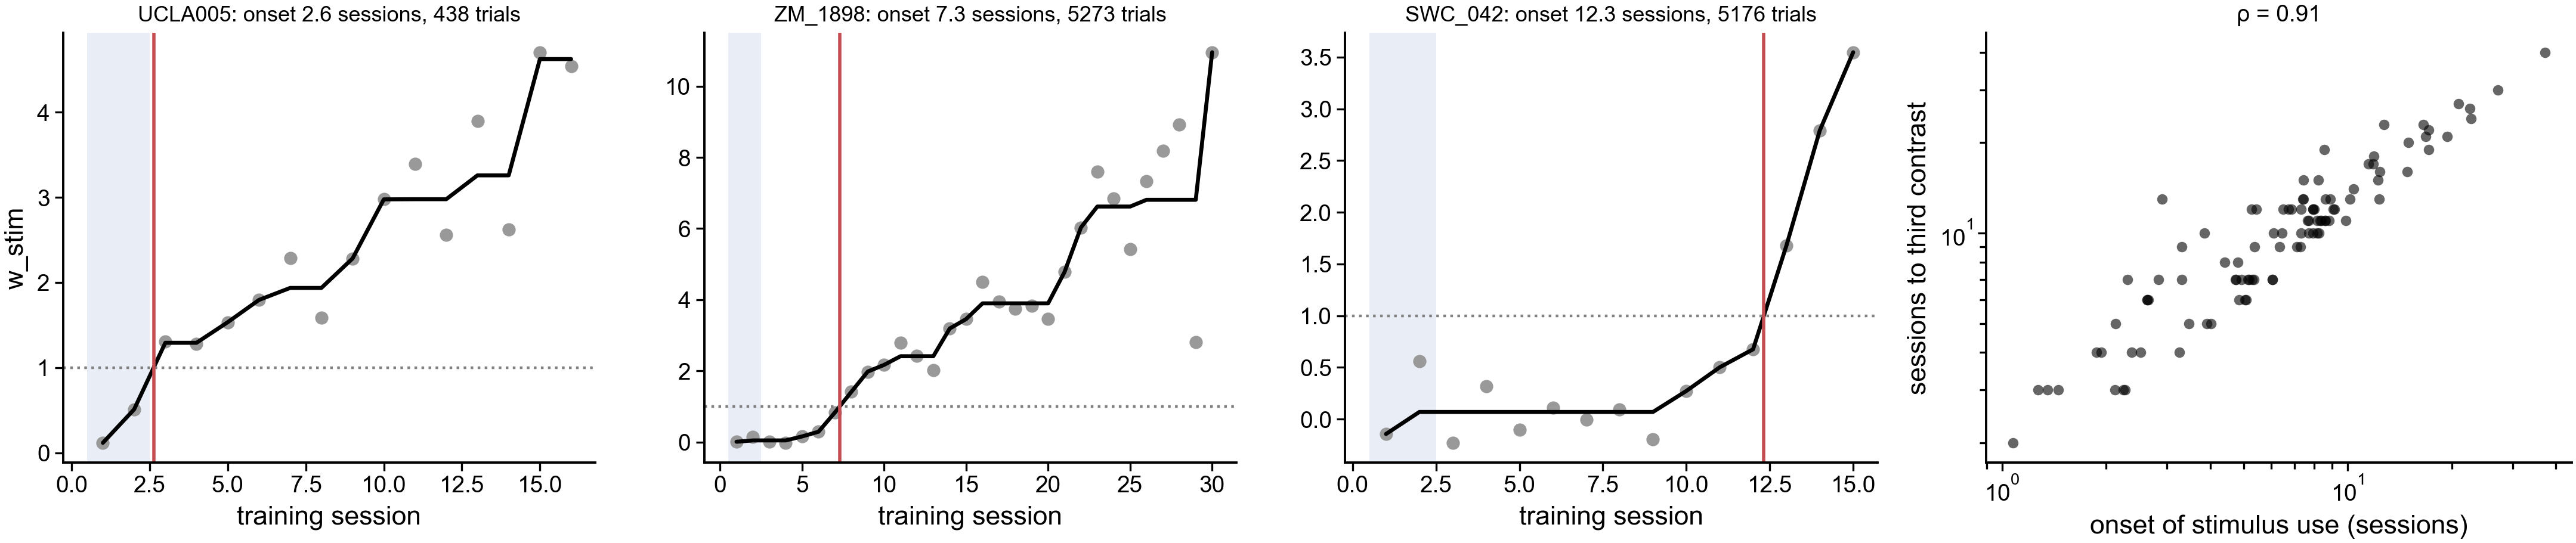

blue band = predictor window (sessions 1-2)


In [2]:
from sklearn.isotonic import IsotonicRegression
order = D.sort_values('onset_sessions')
exm = [order.index[int(q * (len(order) - 1))] for q in (0.15, 0.5, 0.85)]
fig, axs = plt.subplots(1, 4, figsize=(11, 2.5), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.1]))
for ax, m in zip(axs, exm):
    g = S[(S.mouse_name == m) & S.protocol.str.contains('training')].sort_values('session_index').dropna(subset=['w_stim'])
    fit = IsotonicRegression().fit_transform(g.session_index, g.w_stim)
    ax.plot(g.session_index, g.w_stim, 'o', color='0.6', ms=3)
    ax.plot(g.session_index, fit, color='k', lw=1.2)
    ax.axhline(op.ONSET_W, color='0.5', ls=':', lw=0.8)
    ax.axvline(D.loc[m, 'onset_sessions'], color='#C44E52', lw=1)
    ax.axvspan(0.5, 2.5, color='#4C72B0', alpha=0.12, lw=0)
    ax.set_title(f'{m}: onset {D.loc[m, "onset_sessions"]:.1f} sessions, {D.loc[m, "onset_trials"]:.0f} trials', fontsize=6.5)
    ax.set_xlabel('training session')
axs[0].set_ylabel('w_stim')
ax = axs[3]
ax.scatter(D.onset_sessions, D.sessions_to_3c, s=10, color='k', alpha=0.6, lw=0)
r = spearmanr(D.onset_sessions, D.sessions_to_3c, nan_policy='omit')[0]
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('onset of stimulus use (sessions)'); ax.set_ylabel('sessions to third contrast')
ax.set_title(f'ρ = {r:.2f}', fontsize=7)
plt.tight_layout(); plt.show()
print('blue band = predictor window (sessions 1-2)')

## 2. Is it the amount of experience? Onset in trials vs sessions

If slow learners just ran fewer trials per session, they would reach onset after a similar number of
**trials**. In that case onset in trials should vary much less than onset in sessions, and the early
trial rate should predict onset in sessions but not in trials.

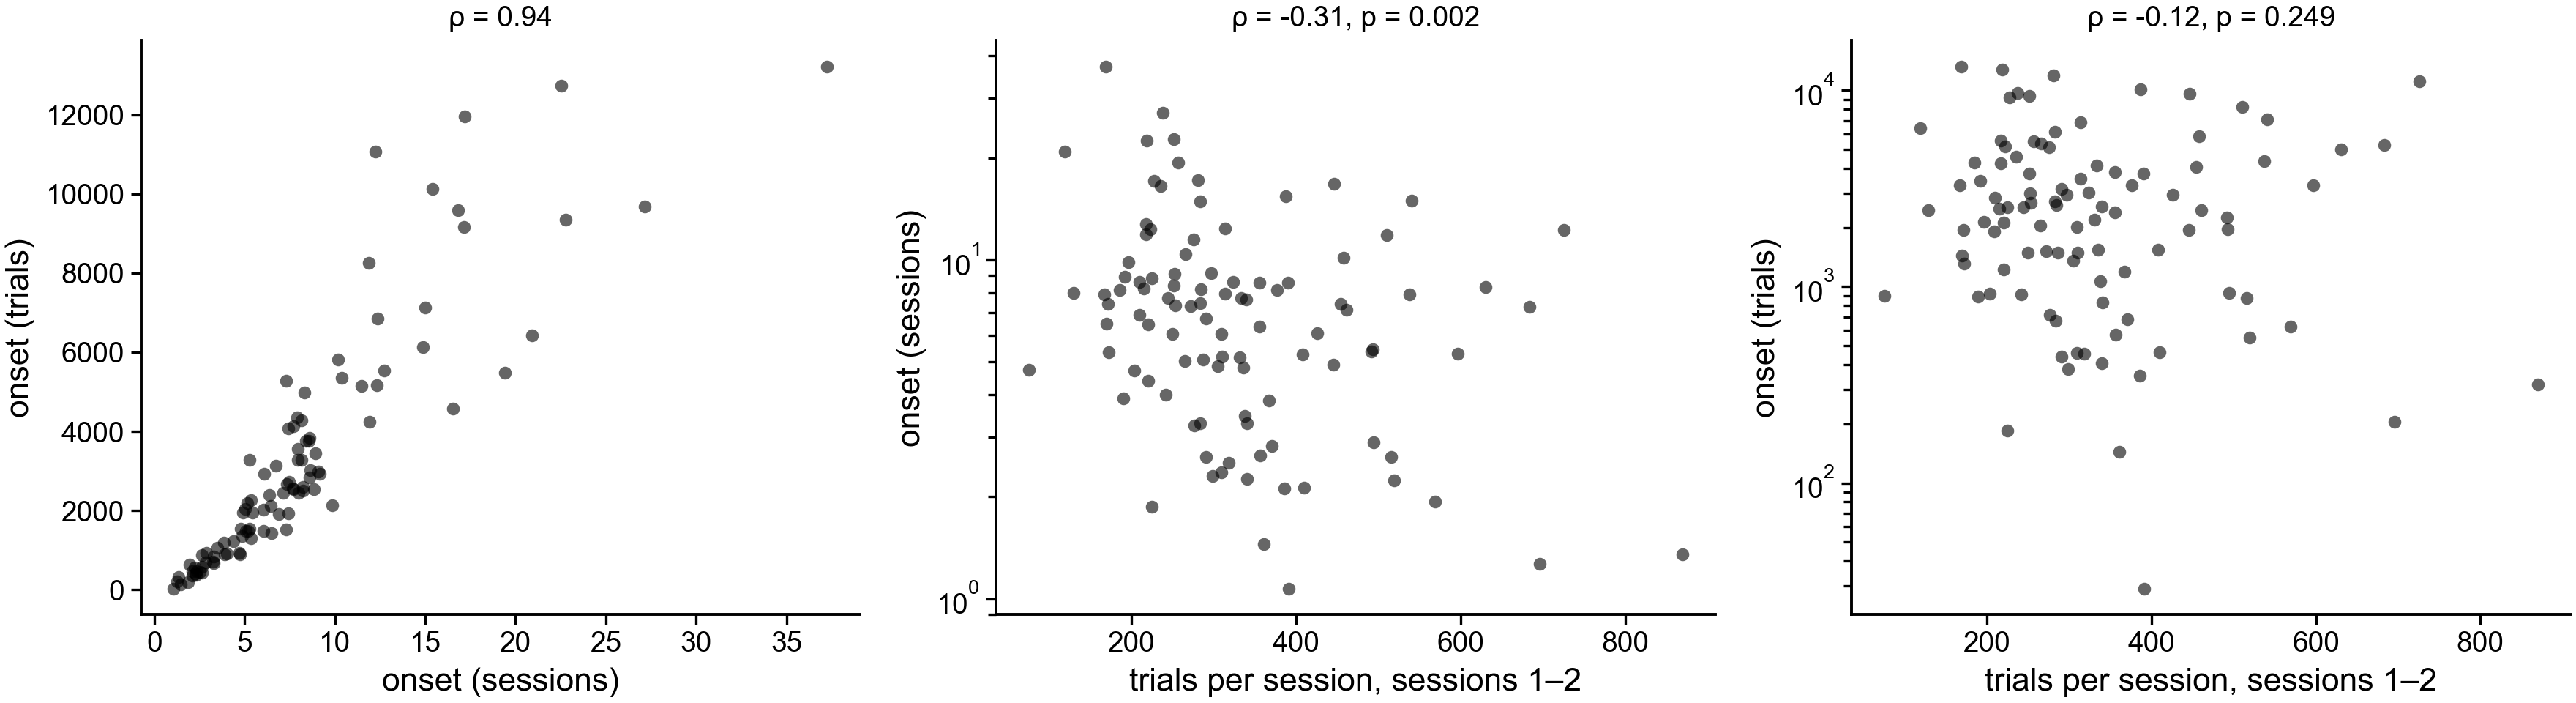

spread across mice (SD of log): onset in sessions 0.71, in trials 1.10


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.6))
ax = axs[0]
ax.scatter(D.onset_sessions, D.onset_trials, s=10, color='k', alpha=0.6, lw=0)
ax.set_xlabel('onset (sessions)'); ax.set_ylabel('onset (trials)')
ax.set_title(f'ρ = {spearmanr(D.onset_sessions, D.onset_trials)[0]:.2f}', fontsize=7)
for ax, y, lbl in [(axs[1], 'onset_sessions', 'onset (sessions)'), (axs[2], 'onset_trials', 'onset (trials)')]:
    ax.scatter(D.trials_per_session, D[y], s=10, color='k', alpha=0.6, lw=0)
    rho, p = spearmanr(D.trials_per_session, D[y])
    ax.set_xlabel('trials per session, sessions 1–2'); ax.set_ylabel(lbl); ax.set_yscale('log')
    ax.set_title(f'ρ = {rho:+.2f}, p = {p:.3f}', fontsize=7)
plt.tight_layout(); plt.show()
cv = lambda x: np.std(np.log(x[x > 0]))
print(f'spread across mice (SD of log): onset in sessions {cv(D.onset_sessions):.2f}, in trials {cv(D.onset_trials):.2f}')

## 3. One predictor at a time

Spearman ρ between each sessions 1–2 measure and onset (sessions), with a 95% bootstrap CI over mice.
**Positive ρ = a higher value goes with a later onset (slower).** BH correction is across all
predictors (reference rows excluded).

Three checks per predictor:
* **onset ≥ 3 sessions only:** drops the mice whose onset falls inside the predictor window.
* **onset in trials** instead of sessions.
* **lab removed:** both variables ranked and residualised on Alyx lab. This is only possible for the
  mice in the LDA cohort, since lab is not in the trial tables (see the `n_lab` column).

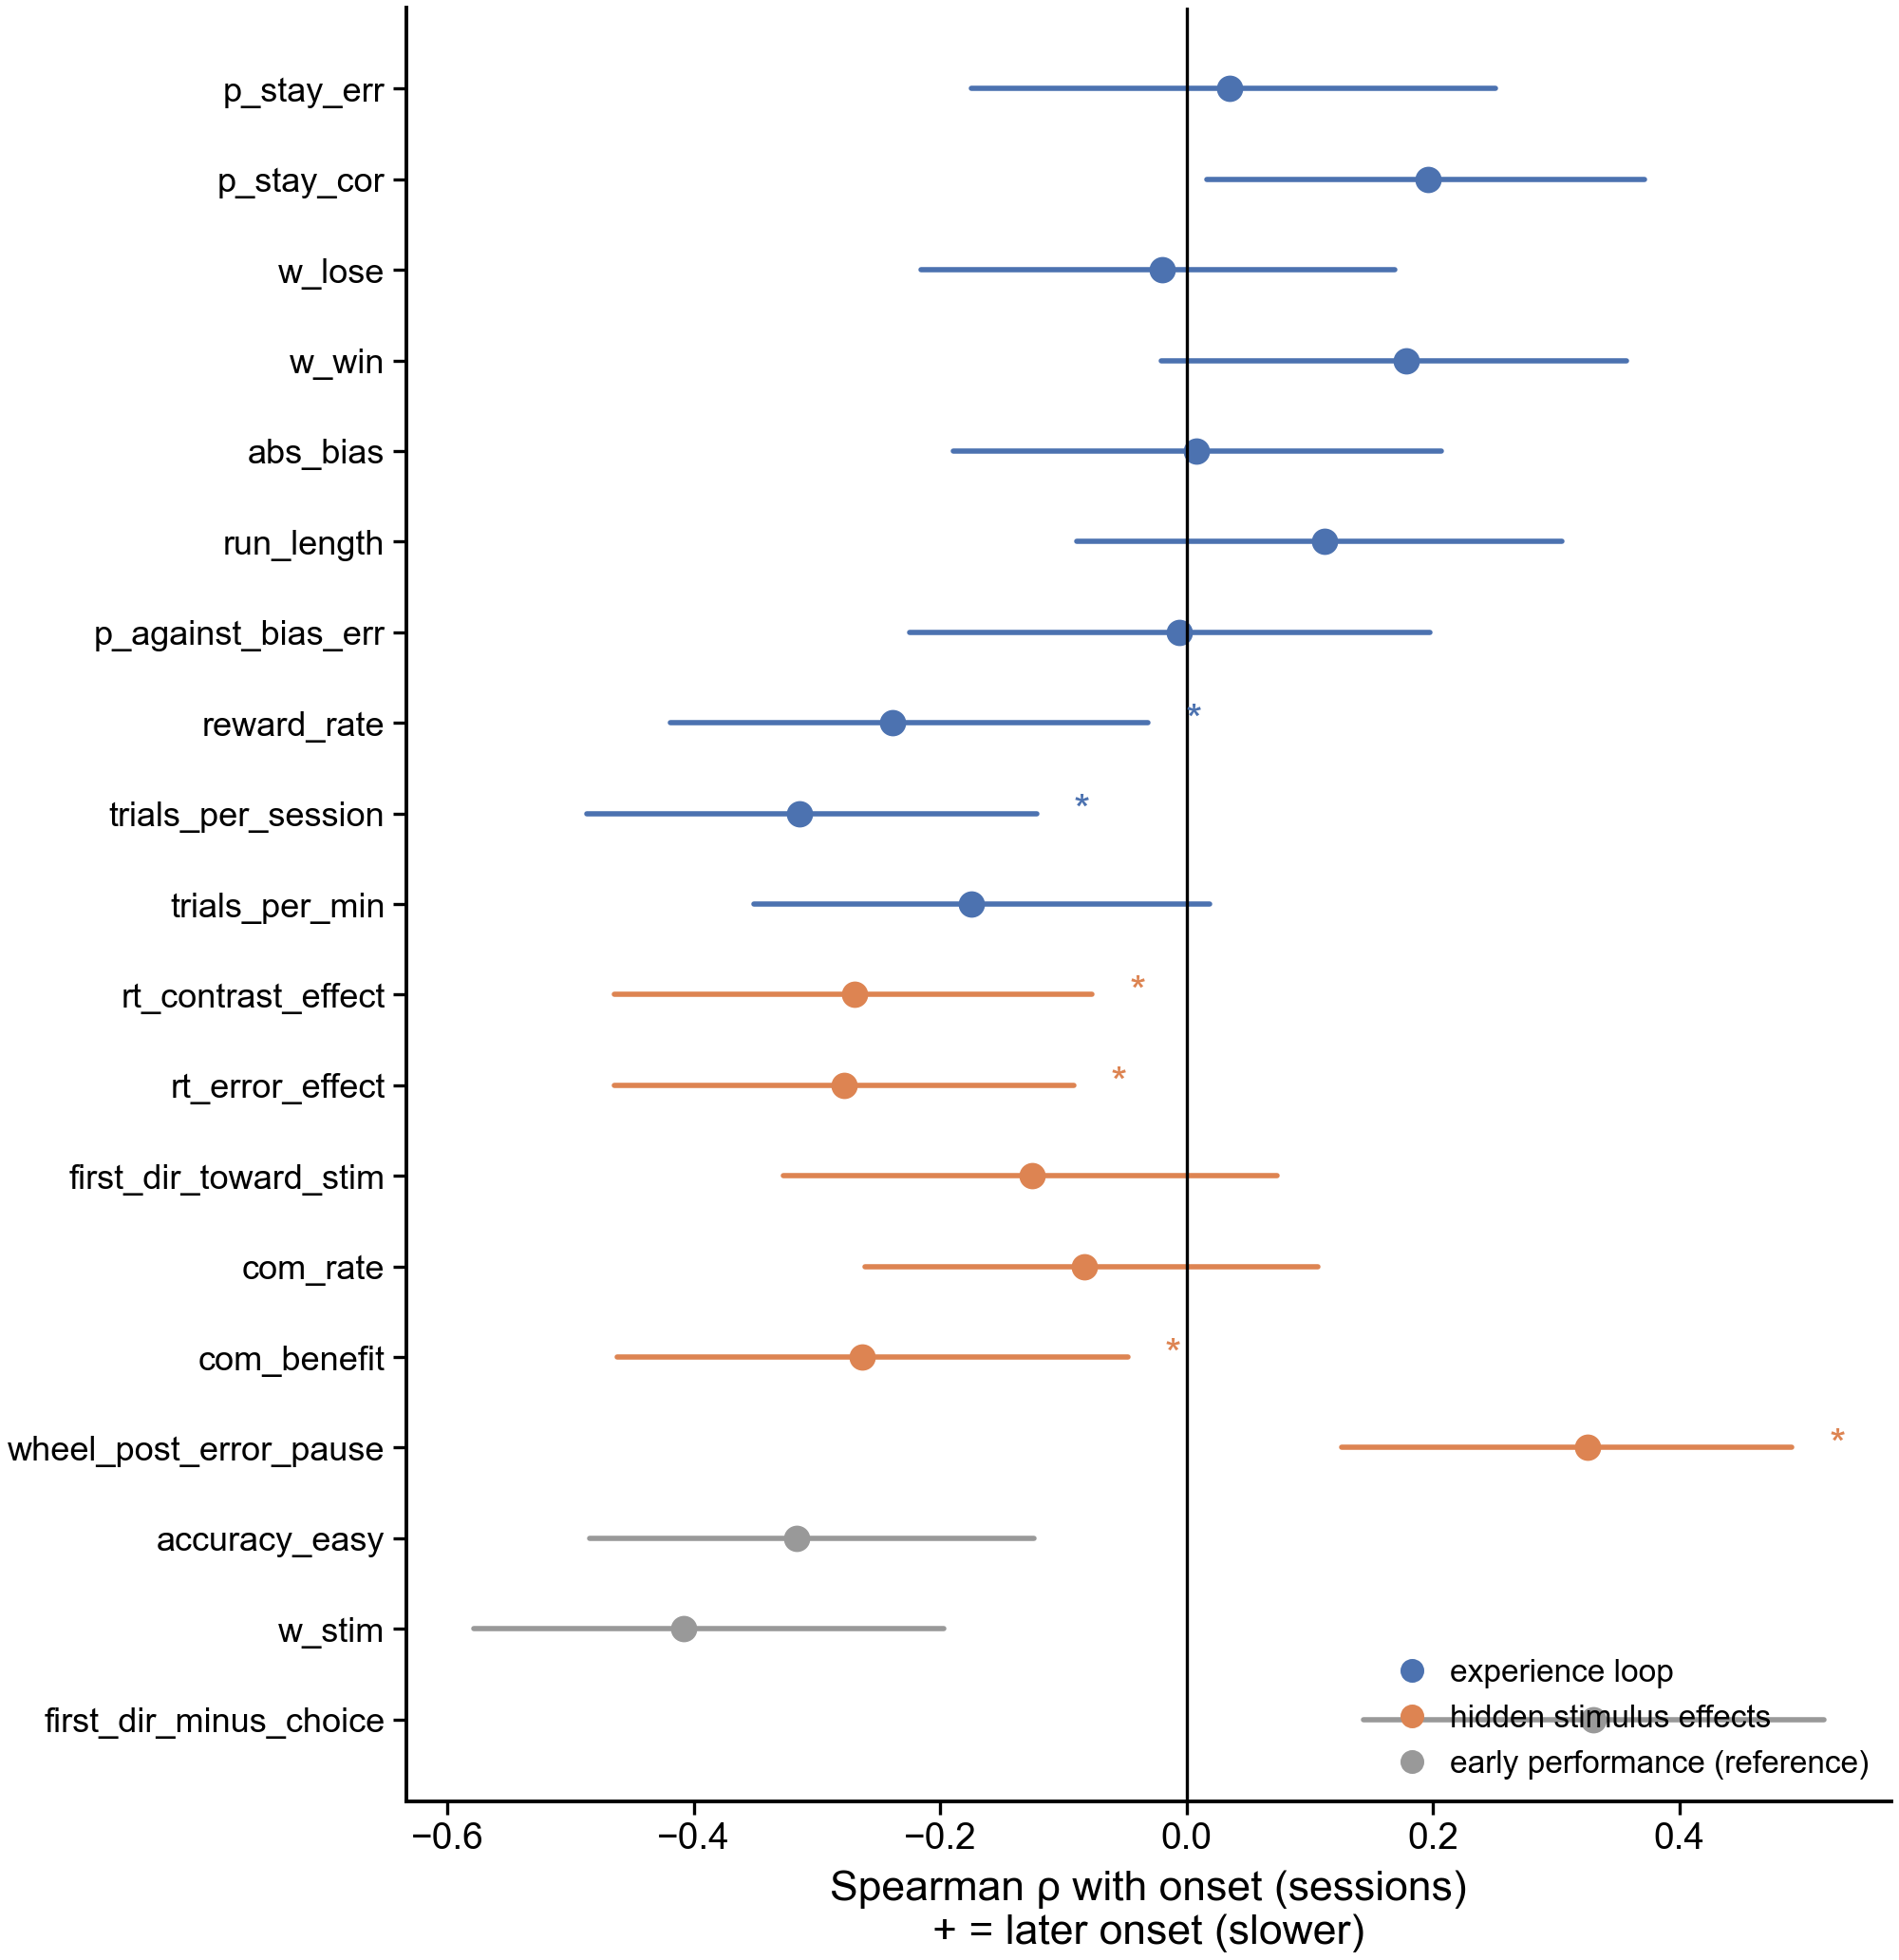

n    rho      p  ci_lo  \
family                        predictor                                         
experience loop               p_stay_err              99  0.035  0.730 -0.175   
                              p_stay_cor              99  0.196  0.052  0.016   
                              w_lose                  99 -0.020  0.845 -0.216   
                              w_win                   99  0.178  0.077 -0.021   
                              abs_bias                99  0.008  0.941 -0.189   
                              run_length              99  0.112  0.270 -0.089   
                              p_against_bias_err      99 -0.006  0.954 -0.225   
                              reward_rate             99 -0.239  0.017 -0.419   
                              trials_per_session      99 -0.314  0.002 -0.487   
                              trials_per_min          99 -0.175  0.083 -0.351   
hidden stimulus effects       rt_contrast_effect      99 -0.270  0.007 -0.465   
                              rt_error_effect         99 -0.278  0.005 -0.464   
                              first_dir_toward_stim   98 -0.125  0.219 -0.328   
                              com_rate                98 -0.083  0.415 -0.261   
                              com_benefit             93 -0.263  0.011 -0.462   
                              wheel_post_error_pause  98  0.326  0.001  0.126   
early performance (reference) accuracy_easy           99 -0.317  0.001 -0.485   
                              w_stim                  99 -0.409  0.000 -0.579   
                              first_dir_minus_choice  98  0.330  0.001  0.143   

                                                      ci_hi  rho_onset_ge3  \
family                        predictor                                      
experience loop               p_stay_err              0.251          0.173   
                              p_stay_cor              0.372          0.307   
                              w_lose                  0.169          0.172   
                              w_win                   0.357          0.262   
                              abs_bias                0.206          0.169   
                              run_length              0.304          0.229   
                              p_against_bias_err      0.197          0.119   
                              reward_rate            -0.031         -0.076   
                              trials_per_session     -0.122         -0.123   
                              trials_per_min          0.019         -0.047   
hidden stimulus effects       rt_contrast_effect     -0.077         -0.197   
                              rt_error_effect        -0.092         -0.143   
                              first_dir_toward_stim   0.073         -0.018   
                              com_rate                0.106         -0.038   
                              com_benefit            -0.048         -0.188   
                              wheel_post_error_pause  0.491          0.168   
early performance (reference) accuracy_easy          -0.124         -0.117   
                              w_stim                 -0.197         -0.101   
                              first_dir_minus_choice  0.517          0.139   

                                                      rho_trials  rho_lab  \
family                        predictor                                     
experience loop               p_stay_err                  -0.028    0.029   
                              p_stay_cor                   0.103    0.224   
                              w_lose                      -0.018   -0.055   
                              w_win                        0.118    0.180   
                              abs_bias                    -0.105    0.075   
                              run_length                   0.034    0.139   
                              p_against_bias_err          -0.051   -0.071   
                     

In [4]:
FAMILIES = {
    'experience loop': ['p_stay_err', 'p_stay_cor', 'w_lose', 'w_win', 'abs_bias', 'run_length',
                        'p_against_bias_err', 'reward_rate', 'trials_per_session', 'trials_per_min'],
    'hidden stimulus effects': ['rt_contrast_effect', 'rt_error_effect', 'first_dir_toward_stim',
                                'com_rate', 'com_benefit', 'wheel_post_error_pause'],
    # first_dir_minus_choice contains choice accuracy by construction (rho = -0.51 with w_stim),
    # so it is performance, not a hidden effect
    'early performance (reference)': ['accuracy_easy', 'w_stim', 'first_dir_minus_choice'],
}
FAM_COL = {'experience loop': '#4C72B0', 'hidden stimulus effects': '#DD8452', 'early performance (reference)': '0.6'}

_argv, sys.argv = sys.argv, ['lab_controls']
import lab_controls as lc
sys.argv = _argv
D['lab'] = lc.MOUSE_LAB


def rank_resid(v, D_):
    return v - D_ @ np.linalg.lstsq(D_, v, rcond=None)[0]


def lab_removed(x, y, labs):
    ok = x.notna() & y.notna() & labs.notna()
    if ok.sum() < 15:
        return np.nan, int(ok.sum())
    Dl = lc._lab_design(labs[ok].to_numpy())
    rx, ry = rank_resid(x[ok].rank().to_numpy(float), Dl), rank_resid(y[ok].rank().to_numpy(float), Dl)
    return float(np.corrcoef(rx, ry)[0, 1]), int(ok.sum())


rng = np.random.default_rng(0)
rows = []
for fam, preds in FAMILIES.items():
    for pr in preds:
        d = D[[pr, 'onset_sessions', 'onset_trials']].dropna()
        rho, p = spearmanr(d[pr], d.onset_sessions)
        boots = []
        for _ in range(1000):
            i = rng.integers(0, len(d), len(d))
            boots.append(spearmanr(d[pr].iloc[i], d.onset_sessions.iloc[i])[0])
        late = d[d.onset_sessions >= 3]
        rl, nl = lab_removed(D[pr], D['onset_sessions'], D['lab'])
        rows.append(dict(family=fam, predictor=pr, n=len(d), rho=rho, p=p,
                         ci_lo=np.nanpercentile(boots, 2.5), ci_hi=np.nanpercentile(boots, 97.5),
                         rho_onset_ge3=spearmanr(late[pr], late.onset_sessions)[0],
                         rho_trials=spearmanr(d[pr], d.onset_trials)[0],
                         rho_lab=rl, n_lab=nl))
R = pd.DataFrame(rows)
test = R.family != 'early performance (reference)'
R.loc[test, 'q'] = multipletests(R.loc[test, 'p'], method='fdr_bh')[1]

fig, ax = plt.subplots(figsize=(5.2, 0.24 * len(R) + 0.8))
yy = np.arange(len(R))[::-1]
for y_, (_, r) in zip(yy, R.iterrows()):
    c = FAM_COL[r.family]
    ax.plot([r.ci_lo, r.ci_hi], [y_, y_], color=c, lw=1)
    ax.plot(r.rho, y_, 'o', color=c, ms=4)
    if r.get('q', 1) < 0.05:
        ax.text(r.ci_hi + 0.03, y_, '*', va='center', color=c)
ax.axvline(0, color='k', lw=0.6)
ax.set_yticks(yy); ax.set_yticklabels(R.predictor, fontsize=6.5)
ax.set_xlabel('Spearman ρ with onset (sessions)\n+ = later onset (slower)')
for fam, c in FAM_COL.items():
    ax.plot([], [], 'o', color=c, label=fam)
ax.legend(fontsize=6, frameon=False, loc='lower right')
plt.tight_layout(); plt.show()
R.set_index(['family', 'predictor']).round(3)

### Nuisance: rig software version

The debiasing rule differs between protocol versions, so the experience-loop measures can depend on
the version a mouse trained on. Version also tracks era and lab.

In [5]:
pv = D.groupby('protocol')['onset_sessions'].agg(['count', 'median']).sort_values('count', ascending=False)
print(pv.round(1).to_string())
big = pv.index[pv['count'] >= 5]
print('Kruskal-Wallis, onset by protocol (versions with >= 5 mice):',
      kruskal(*[D.loc[D.protocol == v, 'onset_sessions'] for v in big]))
print('\nexposure to debiasing by protocol (p_against_bias_err, median):')
print(D.groupby('protocol')['p_against_bias_err'].median().round(3).to_string())

                          count  median
protocol                               
trainingChoiceWorld6.4.2     43     7.3
trainingChoiceWorld          42     6.3
trainingChoiceWorld6.5.3      7     8.3
trainingChoiceWorld6.4.0      4    10.2
trainingChoiceWorld6.5.0      2     5.0
trainingChoiceWorld6.6.2      1     8.8
Kruskal-Wallis, onset by protocol (versions with >= 5 mice): KruskalResult(statistic=3.5510577955047893, pvalue=0.1693938337848258)

exposure to debiasing by protocol (p_against_bias_err, median):
protocol
trainingChoiceWorld         0.699
trainingChoiceWorld6.4.0    0.673
trainingChoiceWorld6.4.2    0.692
trainingChoiceWorld6.5.0    0.724
trainingChoiceWorld6.5.3    0.681
trainingChoiceWorld6.6.2    0.796


### The strongest predictors, as scatter plots

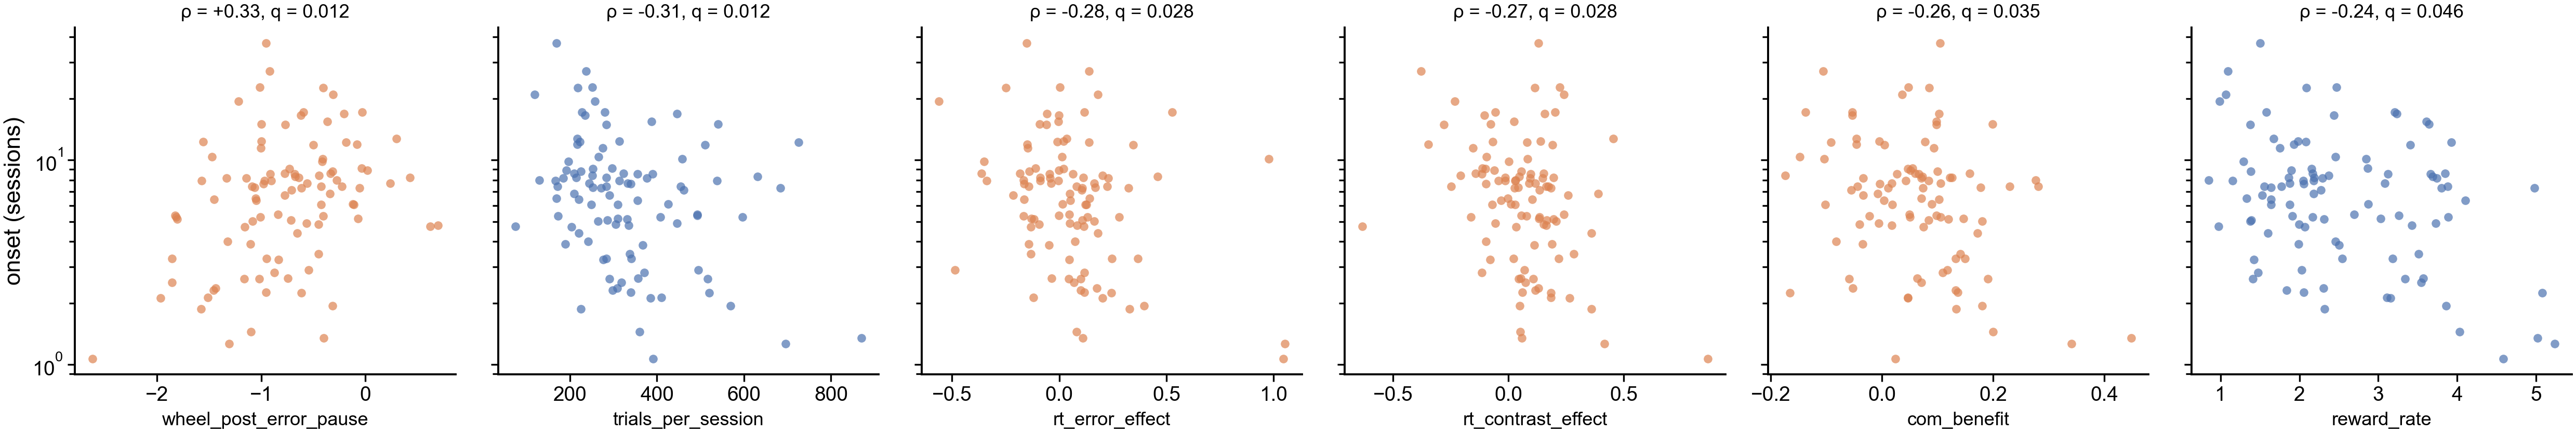

In [6]:
top = R[test].sort_values('p').head(6)
fig, axs = plt.subplots(1, len(top), figsize=(2.1 * len(top), 2.3), sharey=True)
for ax, (_, r) in zip(np.atleast_1d(axs), top.iterrows()):
    d = D[[r.predictor, 'onset_sessions', 'lab']].dropna(subset=[r.predictor, 'onset_sessions'])
    ax.scatter(d[r.predictor], d.onset_sessions, s=9, color=FAM_COL[r.family], alpha=0.7, lw=0)
    ax.set_yscale('log'); ax.set_xlabel(r.predictor, fontsize=6.5)
    ax.set_title(f'ρ = {r.rho:+.2f}, q = {r.q:.3f}', fontsize=6.5)
np.atleast_1d(axs)[0].set_ylabel('onset (sessions)')
plt.tight_layout(); plt.show()

## 4. How predictable is onset from sessions 1–2 overall?

Leave-one-mouse-out ridge regression on z-scored predictors (missing values set to the training
median). The outcome is log onset (sessions). The score is Spearman ρ between held-out predictions and
actual onset. The null refits the whole cross-validation on shuffled outcomes (500 permutations).

Five predictor sets, all fixed in advance by family, not picked from the screen above:
* the experience loop;
* hidden stimulus effects;
* both together;
* **early performance:** sessions 1–2 accuracy and w_stim. This is how much of onset is already
  visible as early learning;
* **early performance + hidden effects:** do the hidden effects add anything beyond early learning?

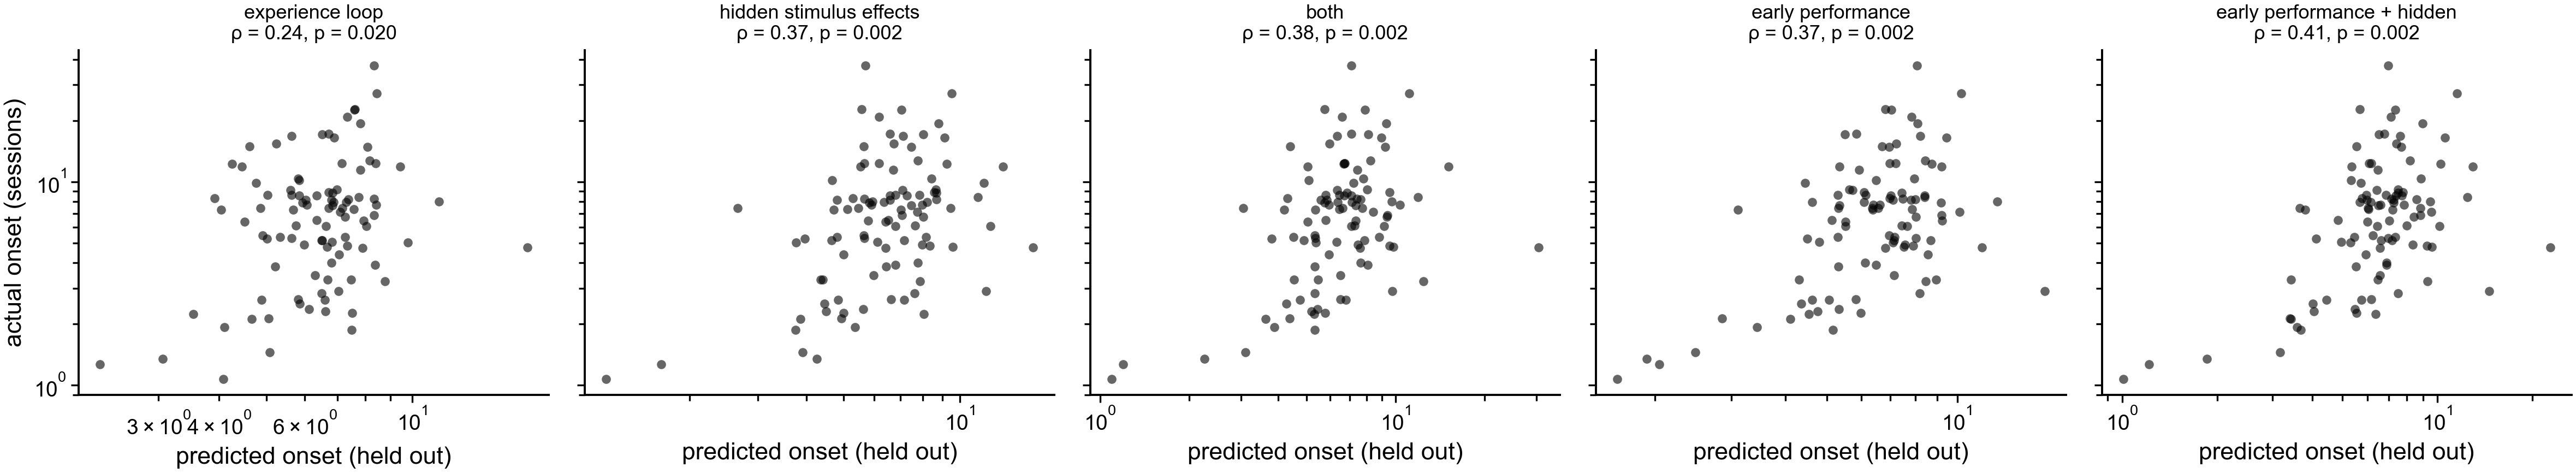

,n_predictors,cv_rho,perm_p,null_95
set,,,,
experience loop,10,0.239,0.020,0.164
hidden stimulus effects,6,0.374,0.002,0.162
both,16,0.380,0.002,0.177
early performance,2,0.372,0.002,0.099
early performance + hidden,8,0.411,0.002,0.179


In [7]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut

y = D['log_onset_s'].to_numpy(float)


def loo_pred(X, y, alpha=10.0):
    pred = np.zeros(len(y))
    for tr, te in LeaveOneOut().split(X):
        Xtr, Xte = X[tr].copy(), X[te].copy()
        med = np.nanmedian(Xtr, 0)
        Xtr = np.where(np.isnan(Xtr), med, Xtr); Xte = np.where(np.isnan(Xte), med, Xte)
        mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
        pred[te] = Ridge(alpha=alpha).fit((Xtr - mu) / sd, y[tr]).predict((Xte - mu) / sd)
    return pred


SETS = {'experience loop': FAMILIES['experience loop'],
        'hidden stimulus effects': FAMILIES['hidden stimulus effects'],
        'both': FAMILIES['experience loop'] + FAMILIES['hidden stimulus effects'],
        'early performance': ['accuracy_easy', 'w_stim'],
        'early performance + hidden': ['accuracy_easy', 'w_stim'] + FAMILIES['hidden stimulus effects']}
N_PERM = 500
cv_rows, preds = [], {}
for name, cols in SETS.items():
    X = D[cols].to_numpy(float)
    pred = loo_pred(X, y)
    rho = spearmanr(pred, y)[0]
    null = np.array([spearmanr(loo_pred(X, yp := rng.permutation(y)), yp)[0] for _ in range(N_PERM)])
    cv_rows.append(dict(set=name, n_predictors=len(cols), cv_rho=rho, perm_p=(1 + np.sum(null >= rho)) / (1 + N_PERM),
                        null_95=np.percentile(null, 95)))
    preds[name] = pred
CV = pd.DataFrame(cv_rows).set_index('set')

fig, axs = plt.subplots(1, len(SETS), figsize=(2.4 * len(SETS), 2.4), sharey=True)
for ax, (name, pred) in zip(axs, preds.items()):
    ax.scatter(np.exp(pred), D.onset_sessions, s=9, color='k', alpha=0.6, lw=0)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('predicted onset (held out)'); ax.set_title(f'{name}\nρ = {CV.loc[name, "cv_rho"]:.2f}, '
                                                              f'p = {CV.loc[name, "perm_p"]:.3f}', fontsize=6.5)
axs[0].set_ylabel('actual onset (sessions)')
plt.tight_layout(); plt.show()
CV.round(3)

## 5. Do the hidden effects change *before* stimulus use, within each mouse?

The between-mouse correlations above say that mice with stronger hidden effects in sessions 1–2
start using the stimulus earlier. A stronger claim is temporal precedence: **within a mouse, do these
effects grow before w_stim does?** The same measures are computed session by session
(`op.build_per_session`), and two analyses follow.

**A. Onset-aligned trajectories.**
* Every session is placed relative to that mouse's onset (session − onset, rounded).
* Each measure is z-scored within mouse, over that mouse's sessions from 8 before to 6 after onset,
  and signed so that **up = the direction that predicted an early onset**:
  * slower responses to weaker contrast;
  * slower errors;
  * changes of mind that help;
  * a longer post-error pause (the negative log ratio).
* A leading indicator should rise in the sessions before 0, while w_stim is still near its floor.
* Only mice with onset ≥ 4 sessions are used, so every mouse has at least 3 pre-onset sessions.

**B. Cross-lagged regression within mice**, over sessions up to 2 after onset. Both variables are
demeaned within mouse and z-scored, and 95% CIs come from resampling mice.
* **hidden → stimulus:** does a measure at session k predict the change in w_stim from k to k+1,
  given w_stim at k?
* **stimulus → hidden:** does w_stim at k predict the change in the measure, given the measure at k?

Precedence means the first coefficient is positive and larger than the second. Accuracy is included as
a reference, since it is another face of stimulus use.

Lagged regressions with mouse-demeaning have a known small bias (Nickell bias) on the
own-lag terms. The cross terms that matter here are less affected, but read them as descriptive.

75 mice with onset >= 4 sessions


first session (relative to onset) at which the mean rises > 0.5 z above its pre-onset baseline (rel <= -5):
w_stim                     0.0
accuracy (easy)            0.0
RT(0.5) − RT(1.0)          NaN
RT(error) − RT(correct)    2.0
change-of-mind benefit     NaN
post-error wheel pause     NaN


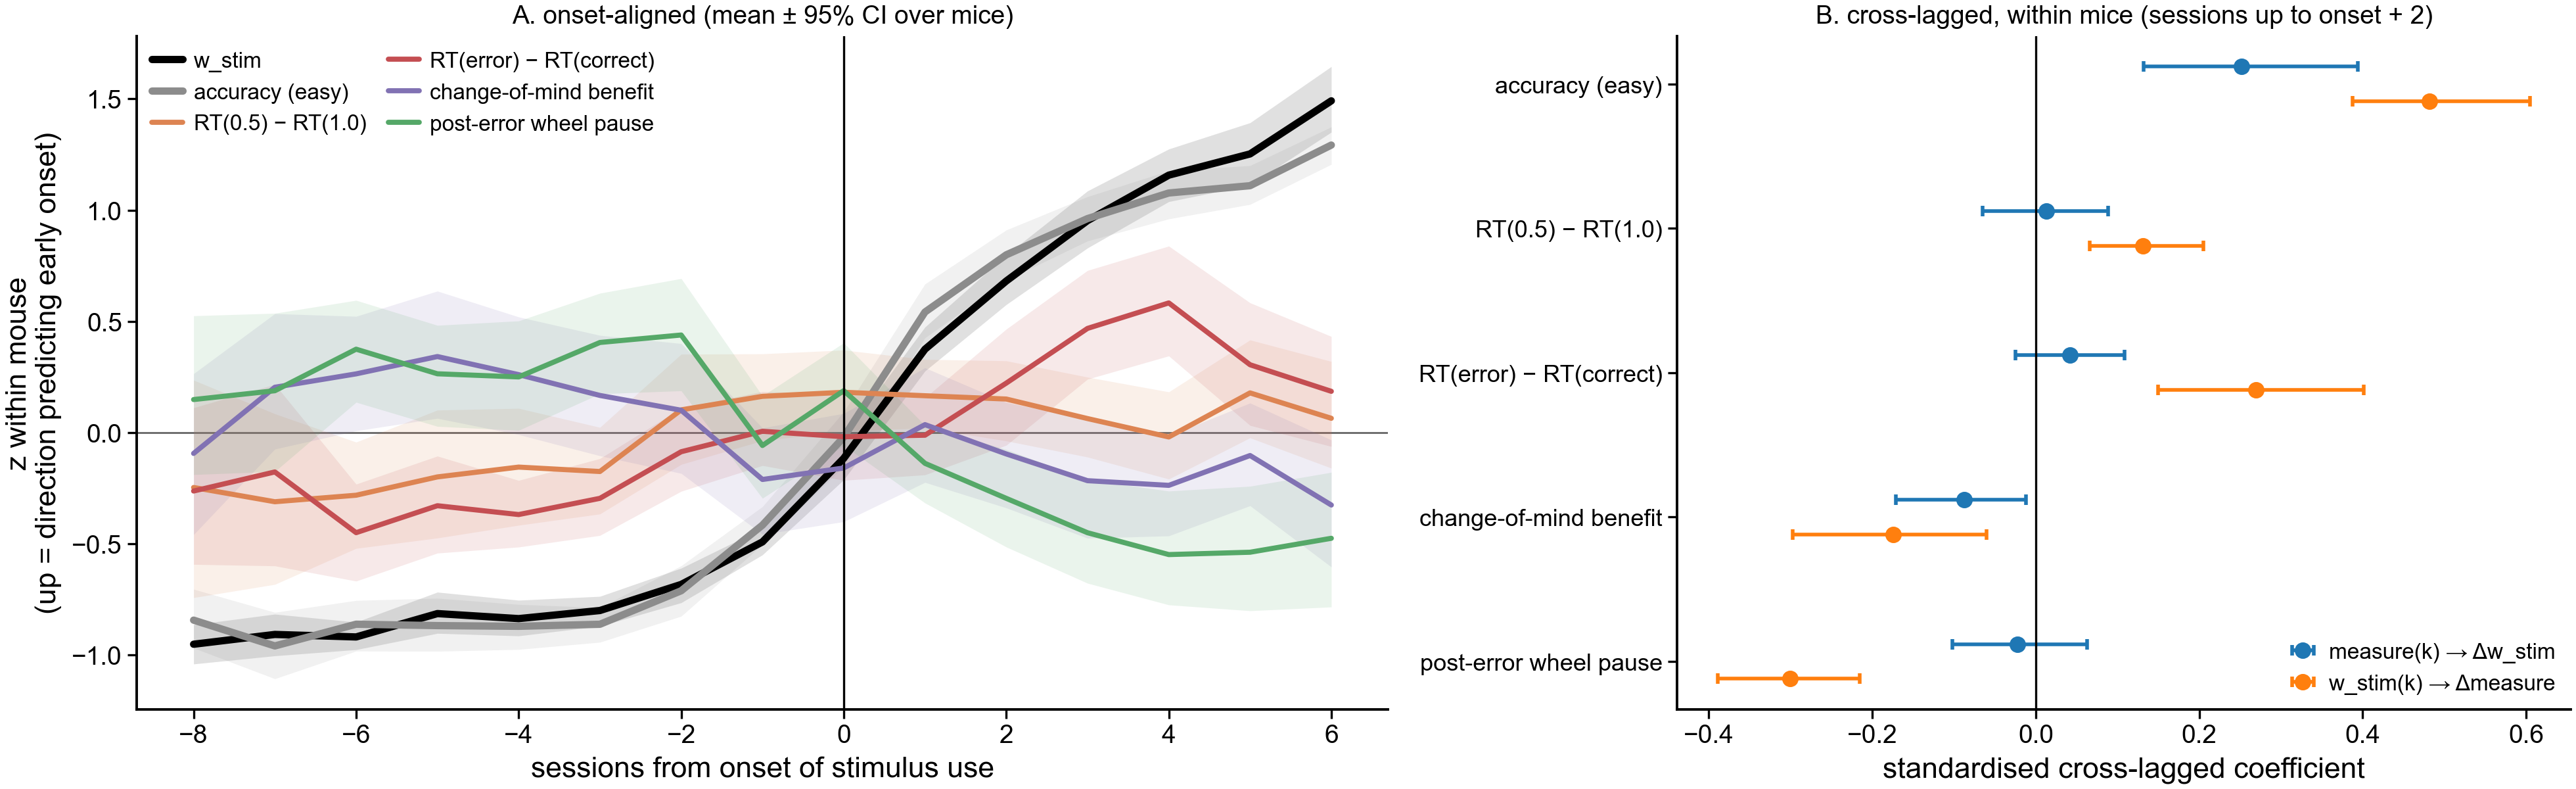

,n_mice,n_pairs,h_to_w,h_to_w_lo,h_to_w_hi,w_to_h,w_to_h_lo,w_to_h_hi,p_diff
measure,,,,,,,,,
accuracy (easy),99,870,0.252,0.132,0.394,0.482,0.388,0.605,0.995
RT(0.5) − RT(1.0),99,868,0.013,-0.065,0.089,0.131,0.066,0.205,0.982
RT(error) − RT(correct),99,867,0.042,-0.025,0.108,0.269,0.150,0.402,0.999
change-of-mind benefit,91,579,-0.087,-0.171,-0.012,-0.174,-0.298,-0.060,0.086
post-error wheel pause,94,608,-0.023,-0.102,0.063,-0.301,-0.389,-0.216,0.000


In [8]:
Q = op.build_per_session()          # cached; op.build_per_session(refresh=True) recomputes (~1 min)
Q = Q.merge(D[['onset_sessions']], left_on='mouse_name', right_index=True)
Q['rel'] = np.round(Q['session_index'] - Q['onset_sessions']).astype(int)
Q['pause'] = -Q['wheel_post_error_pause']            # up = longer post-error pause
HID = {'rt_contrast_effect': 'RT(0.5) − RT(1.0)', 'rt_error_effect': 'RT(error) − RT(correct)',
       'com_benefit': 'change-of-mind benefit', 'pause': 'post-error wheel pause'}
REF = {'w_stim': 'w_stim', 'accuracy_easy': 'accuracy (easy)'}
ALLM = {**REF, **HID}
WIN = (-8, 6)

A = Q[(Q.onset_sessions >= 4) & Q.rel.between(*WIN)].copy()
for c in ALLM:
    A[c + '_z'] = A.groupby('mouse_name')[c].transform(lambda x: (x - x.mean()) / x.std() if x.std() > 0 else np.nan)
print(f"{A.mouse_name.nunique()} mice with onset >= 4 sessions")

rng = np.random.default_rng(0)
COLS = {'w_stim': 'k', 'accuracy_easy': '0.55', 'rt_contrast_effect': '#DD8452', 'rt_error_effect': '#C44E52',
        'com_benefit': '#8172B3', 'pause': '#55A868'}
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax = axs[0]
summ = {}
for c in ALLM:
    pm = A.groupby(['rel', 'mouse_name'])[c + '_z'].mean().dropna()
    g = pm.groupby('rel')
    m_, n_ = g.mean(), g.size()
    lo, hi = [], []
    for r_, vals in g:
        b = [rng.choice(vals.to_numpy(), len(vals)).mean() for _ in range(500)]
        lo.append(np.percentile(b, 2.5)); hi.append(np.percentile(b, 97.5))
    keep = n_ >= 8
    ax.plot(m_.index[keep], m_[keep], color=COLS[c], lw=2 if c in REF else 1.4, label=ALLM[c])
    ax.fill_between(m_.index[keep], np.array(lo)[keep], np.array(hi)[keep], color=COLS[c], alpha=0.12, lw=0)
    summ[c] = m_
ax.axvline(0, color='k', lw=0.6); ps.zero_line(ax)
ax.set_xlabel('sessions from onset of stimulus use'); ax.set_ylabel('z within mouse\n(up = direction predicting early onset)')
ax.legend(fontsize=6, frameon=False, ncol=2)
ax.set_title('A. onset-aligned (mean ± 95% CI over mice)', fontsize=7)

# when does each measure leave its early baseline? first rel whose mean is > 0.5 z above the rel <= -5 mean
base = {c: summ[c][summ[c].index <= -5].mean() for c in ALLM}
lead = {c: next((int(r_) for r_, v in summ[c].items() if r_ > -5 and v - base[c] > 0.5), np.nan) for c in ALLM}
print('first session (relative to onset) at which the mean rises > 0.5 z above its pre-onset baseline (rel <= -5):')
print(pd.Series(lead).rename(ALLM).to_string())

# B. cross-lagged
B_ = Q[Q.rel <= 2].sort_values(['mouse_name', 'session_index']).copy()
B_['next_sess'] = B_.groupby('mouse_name')['session_index'].shift(-1)


def crosslag(df, h, w='w_stim', n_boot=1000):
    d = df[['mouse_name', 'session_index', 'next_sess', h, w]].copy()
    for c in (h, w):
        d[c + '_next'] = df.groupby('mouse_name')[c].shift(-1)
    d = d[(d['next_sess'] == d['session_index'] + 1)].dropna()
    for c in (h, w, h + '_next', w + '_next'):
        d[c] = d[c] - d.groupby('mouse_name')[c].transform('mean')
    sd = {c: d[c].std() for c in (h, w)}
    for c in (h, w):
        d[c] /= sd[c]; d[c + '_next'] /= sd[c]

    def fit(dd):
        X1 = np.column_stack([dd[h], dd[w]]); y1 = dd[w + '_next'] - dd[w]
        X2 = np.column_stack([dd[w], dd[h]]); y2 = dd[h + '_next'] - dd[h]
        return (np.linalg.lstsq(X1, y1, rcond=None)[0][0], np.linalg.lstsq(X2, y2, rcond=None)[0][0])

    est = fit(d)
    mice = d['mouse_name'].unique(); grp = {m: d[d.mouse_name == m] for m in mice}
    boot = np.array([fit(pd.concat([grp[m] for m in rng.choice(mice, len(mice))])) for _ in range(n_boot)])
    return dict(measure=ALLM[h], n_mice=len(mice), n_pairs=len(d),
                h_to_w=est[0], h_to_w_lo=np.percentile(boot[:, 0], 2.5), h_to_w_hi=np.percentile(boot[:, 0], 97.5),
                w_to_h=est[1], w_to_h_lo=np.percentile(boot[:, 1], 2.5), w_to_h_hi=np.percentile(boot[:, 1], 97.5),
                p_diff=np.mean((boot[:, 0] - boot[:, 1]) <= 0))


CL = pd.DataFrame([crosslag(B_, h) for h in ['accuracy_easy'] + list(HID)]).set_index('measure')
ax = axs[1]
yy = np.arange(len(CL))[::-1]
for k, (lbl, col) in enumerate([('h_to_w', '#1F77B4'), ('w_to_h', '#FF7F0E')]):
    ax.errorbar(CL[lbl], yy + (0.12 if k == 0 else -0.12),
                xerr=[CL[lbl] - CL[lbl + '_lo'], CL[lbl + '_hi'] - CL[lbl]], fmt='o', color=col, ms=3.5, lw=1,
                label='measure(k) → Δw_stim' if k == 0 else 'w_stim(k) → Δmeasure')
ax.axvline(0, color='k', lw=0.6)
ax.set_yticks(yy); ax.set_yticklabels(CL.index, fontsize=6.5)
ax.set_xlabel('standardised cross-lagged coefficient'); ax.legend(fontsize=6, frameon=False, loc='lower right')
ax.set_title('B. cross-lagged, within mice (sessions up to onset + 2)', fontsize=7)
plt.tight_layout(); plt.show()
CL.round(3)

## Observations (exploratory: 99 mice, one fixed early window, not pre-registered)

**1. It is not just the amount of experience.**
* Onset measured in trials varies across mice *more* than onset in sessions (SD of log 1.10 vs 0.71),
  so slow learners need more trials, not just more sessions.
* Trials per session in sessions 1–2 predicts onset in sessions (ρ = −0.31, q = 0.01) but not in trials
  (ρ = −0.12). So part of the session count is pacing (mice that run more trials per session get there
  in fewer sessions), but pacing does not explain how much experience a mouse needs.

**2. The experience loop with the debiasing protocol does not predict onset.** Side bias, stay
probabilities after errors and after corrects, history weights, choice run length, and how often the
stimulus was placed against the mouse's bias are all within |ρ| ≤ 0.2 (q > 0.1). Reward rate is weakly
predictive (ρ = −0.24, q = 0.046), but it tracks trials per session (ρ = 0.71). As a family, the
cross-validated prediction is modest (ρ = 0.24).

**3. Hidden stimulus effects predict it.** These are signs that the stimulus registers before choices
follow it. The mice that show them in sessions 1–2 start using the stimulus sooner:
* **Reaction time depends on contrast:** slower responses to 0.5 than to 1.0 contrast go with earlier
  onset (ρ = −0.27, q = 0.03). It is unrelated to early choice performance (ρ = 0.08 with sessions 1–2
  w_stim), and strongest with lab removed (ρ = −0.43, n = 53).
* **Errors are slower than correct responses** (ρ = −0.28, q = 0.03).
* **Changes of mind help:** when the first wheel movement reverses, the final choice is more often
  correct (ρ = −0.26, q = 0.035).
* **Post-error wheel pause:** mice that pause more after errors start sooner (ρ = +0.33 on the log
  ratio, q = 0.01; lab removed +0.33). This is the effect seen in notebooks 2 and 3, now as a predictor.

**4. Together they predict onset as well as early performance does, and add to it.**
* Cross-validated ρ (leave one mouse out): hidden effects 0.37, early performance (sessions 1–2
  accuracy and w_stim) 0.37, both together 0.41. All have permutation p ≈ 0.002.
* The hidden effects are only weakly related to early performance (|ρ| ≤ 0.27), so they carry partly
  separate information.

**5. Temporal precedence within mice (section 5): the hidden effects do not lead stimulus use.**
* **Onset-aligned (75 mice with onset ≥ 4 sessions):** none of the four measures rises before onset
  while w_stim is still at its floor.
  * The reaction-time effect of contrast drifts up a little from about −3 sessions, roughly together
    with w_stim.
  * The error-vs-correct reaction-time effect rises *after* onset (+2 sessions).
  * The post-error wheel pause and the change-of-mind benefit *fall* after onset.
* **Cross-lagged:** none of the hidden measures predicts the next-session change in w_stim (all CIs
  include 0; change-of-mind benefit is slightly negative). In the other direction, w_stim predicts later
  changes in every one of them: the RT effects grow, while the pause and the change-of-mind benefit
  shrink. Accuracy, the positive control, does predict the next change in w_stim (+0.25).
* **Reading:** within a mouse these measures *follow* stimulus use, or move with it; they don't
  precede it. Their between-mouse predictive value therefore looks like a **trait**, a stable
  difference between mice already visible in sessions 1–2, rather than an early stage of the same
  learning process.
  * The post-error pause makes the dissociation explicit. Mice that pause more early on learn sooner,
    yet within each mouse the pause shrinks as it starts using the stimulus.
* **Caveat:** the per-session hidden measures are much noisier than w_stim. Noise in a predictor
  shrinks its cross-lagged coefficient, so the hidden → stimulus test is the weaker of the two. The
  onset-aligned curves don't depend on that, though, and they show no lead either.

**Caveats.**
* Everything shrinks when the 12 mice that reach onset by session 2.5 are dropped (e.g. reaction time
  by contrast −0.27 → −0.20, post-error pause +0.33 → +0.17). Some of that is lost range, but these
  are moderate effects at best.
* Lab is only known for the 53 mice in the LDA cohort.
* Protocol version does not predict onset (Kruskal–Wallis p = 0.17).
* The reaction-time effect of contrast could also reflect visual detection speed rather than
  stimulus "registration" in a cognitive sense.

**Reading, in the representation-learning frame.** Before the stimulus drives the choice, it already
shapes the timing of behaviour: how fast the mouse responds, whether it corrects mid-movement, and how
it behaves after an error. Mice in which that happens early go on to use the stimulus sooner. This fits
a picture where the stimulus is perceived early, and the slow step is making it part of the state that
the choice policy depends on, rather than detecting it at all.

**Next.**
1. ~~Temporal precedence within each mouse~~: done (point 5); not supported.
2. **Lab for all 99 mice** (needs Alyx on the analysis machine), to redo the lab-removed checks with
   full power.